# Customer Segmentation for Marketing

**Goal:** split an 8,000-customer retail base into segments that behave differently,
explain what drives each segment, and use them to target a promotional campaign.

**Approach**

1. Explore the (mock) customer data
2. Baseline: classic rule-based **RFM** segmentation
3. Behavioural clustering: choose *k* with four criteria, compare **K-Means**, **Gaussian Mixture** and **Ward hierarchical** clustering
4. Profile and name the segments
5. **Random forest** to explain the segments and assign new customers
6. **Campaign response models** (logistic regression vs gradient boosting) with lift / gains analysis
7. Marketing playbook per segment

> The data is synthetic (`segmentation.data.generate_customers`). Each customer was drawn from one of
> five hidden personas, which lets us check how well unsupervised methods recover real structure,
> something that's impossible with production data.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.decomposition import PCA

from segmentation import DATA_PROCESSED
from segmentation.data import load_customers
from segmentation.features import CLUSTER_FEATURES, PROFILE_FEATURES, cluster_preprocessor, rfm_scores
from segmentation.clustering import (
    evaluate_k, stability_by_k, gmm_bic, compare_algorithms,
    index_vs_average, profile_segments, name_segments,
)
from segmentation.models import train_segment_classifier, train_response_models, gains_table
from segmentation import plotting as P

P.set_style()
pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_columns", 40)

## 1. Data overview

In [2]:
df = load_customers()
print(f"{len(df):,} customers x {df.shape[1]} columns")
df.drop(columns="true_persona").head()

8,000 customers x 26 columns


,customer_id,age,gender,region,income_k,tenure_months,recency_days,frequency_12m,monetary_12m,avg_order_value,discount_usage_rate,web_sessions_month,app_sessions_month,email_open_rate,email_click_rate,social_engagement,support_tickets_12m,nps_score,preferred_channel,share_electronics,share_apparel,share_home,share_beauty,responded_campaign,churned_6m
0,C000001,47,M,West,78.00,26,8,23,670.47,29.15,0.95,18,7,0.22,0.09,0,0,6,app,0.18,0.38,0.31,0.13,0,0
1,C000002,20,F,Northeast,43.50,45,35,16,238.20,14.89,0.83,11,3,0.64,0.35,1,1,5,web,0.35,0.16,0.23,0.26,0,0
2,C000003,33,M,West,32.40,42,14,63,610.07,9.68,0.79,6,4,0.37,0.09,1,0,7,store,0.23,0.04,0.17,0.56,0,0
3,C000004,53,M,Southwest,103.80,20,83,20,363.64,18.18,0.78,19,0,0.74,0.11,1,0,8,store,0.19,0.48,0.18,0.15,0,0
4,C000005,20,F,West,83.60,20,58,5,233.27,46.65,0.26,0,11,0.07,0.03,48,0,9,web,0.29,0.41,0.01,0.29,0,0


In [3]:
df.drop(columns=["customer_id", "true_persona"]).describe().T[["mean", "std", "min", "50%", "max"]]

,mean,std,min,50%,max
age,38.56,12.29,18.00,38.00,83.00
income_k,74.29,42.56,13.50,62.85,434.80
tenure_months,33.71,23.13,1.00,28.00,180.00
recency_days,83.18,134.91,0.00,30.00,730.00
frequency_12m,10.79,13.20,1.00,5.00,107.00
monetary_12m,"1,035.19","2,031.42",8.87,404.16,"44,003.00"
avg_order_value,114.24,142.29,5.52,64.19,"2,008.64"
discount_usage_rate,0.39,0.28,0.00,0.34,1.00
web_sessions_month,5.94,7.44,0.00,3.00,70.00
app_sessions_month,6.17,10.51,0.00,2.00,158.00


In [4]:
kpis = pd.Series({
    "Customers": f"{len(df):,}",
    "Revenue (12m)": f"${df.monetary_12m.sum() / 1e6:.1f}M",
    "Avg revenue / customer": f"${df.monetary_12m.mean():,.0f}",
    "Campaign response rate": f"{df.responded_campaign.mean():.1%}",
    "6-month churn rate": f"{df.churned_6m.mean():.1%}",
})
kpis.to_frame("value")

,value
Customers,"8,000"
Revenue (12m),$8.3M
Avg revenue / customer,"$1,035"
Campaign response rate,26.6%
6-month churn rate,15.2%


### Distributions of the behavioural features

Most behavioural measures are strongly right-skewed (a few very active or high-spend customers),
so they are log-transformed before clustering.

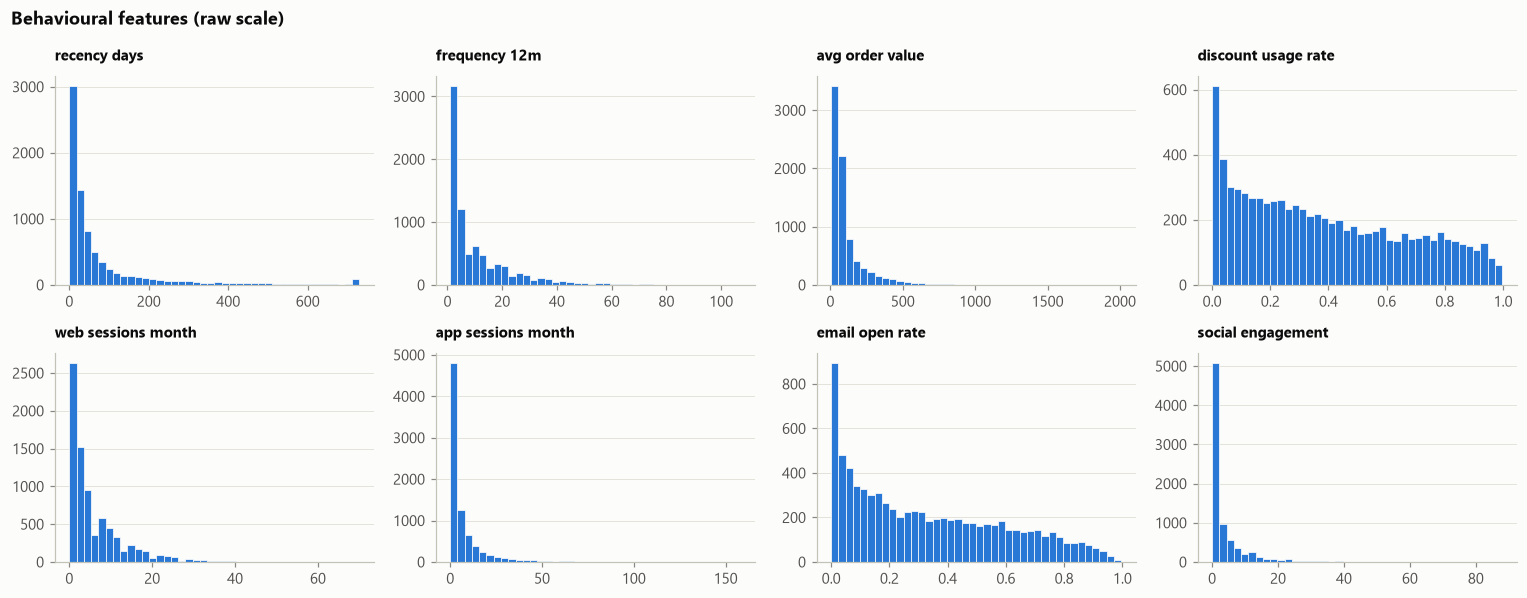

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(14, 5.5))
for ax, col in zip(axes.flat, CLUSTER_FEATURES):
    ax.hist(df[col], bins=40, color=P.SEQ, edgecolor=P.SURFACE, linewidth=0.5)
    ax.set_title(col.replace("_", " "), fontsize=10)
    ax.grid(axis="x", visible=False)
fig.suptitle("Behavioural features (raw scale)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()

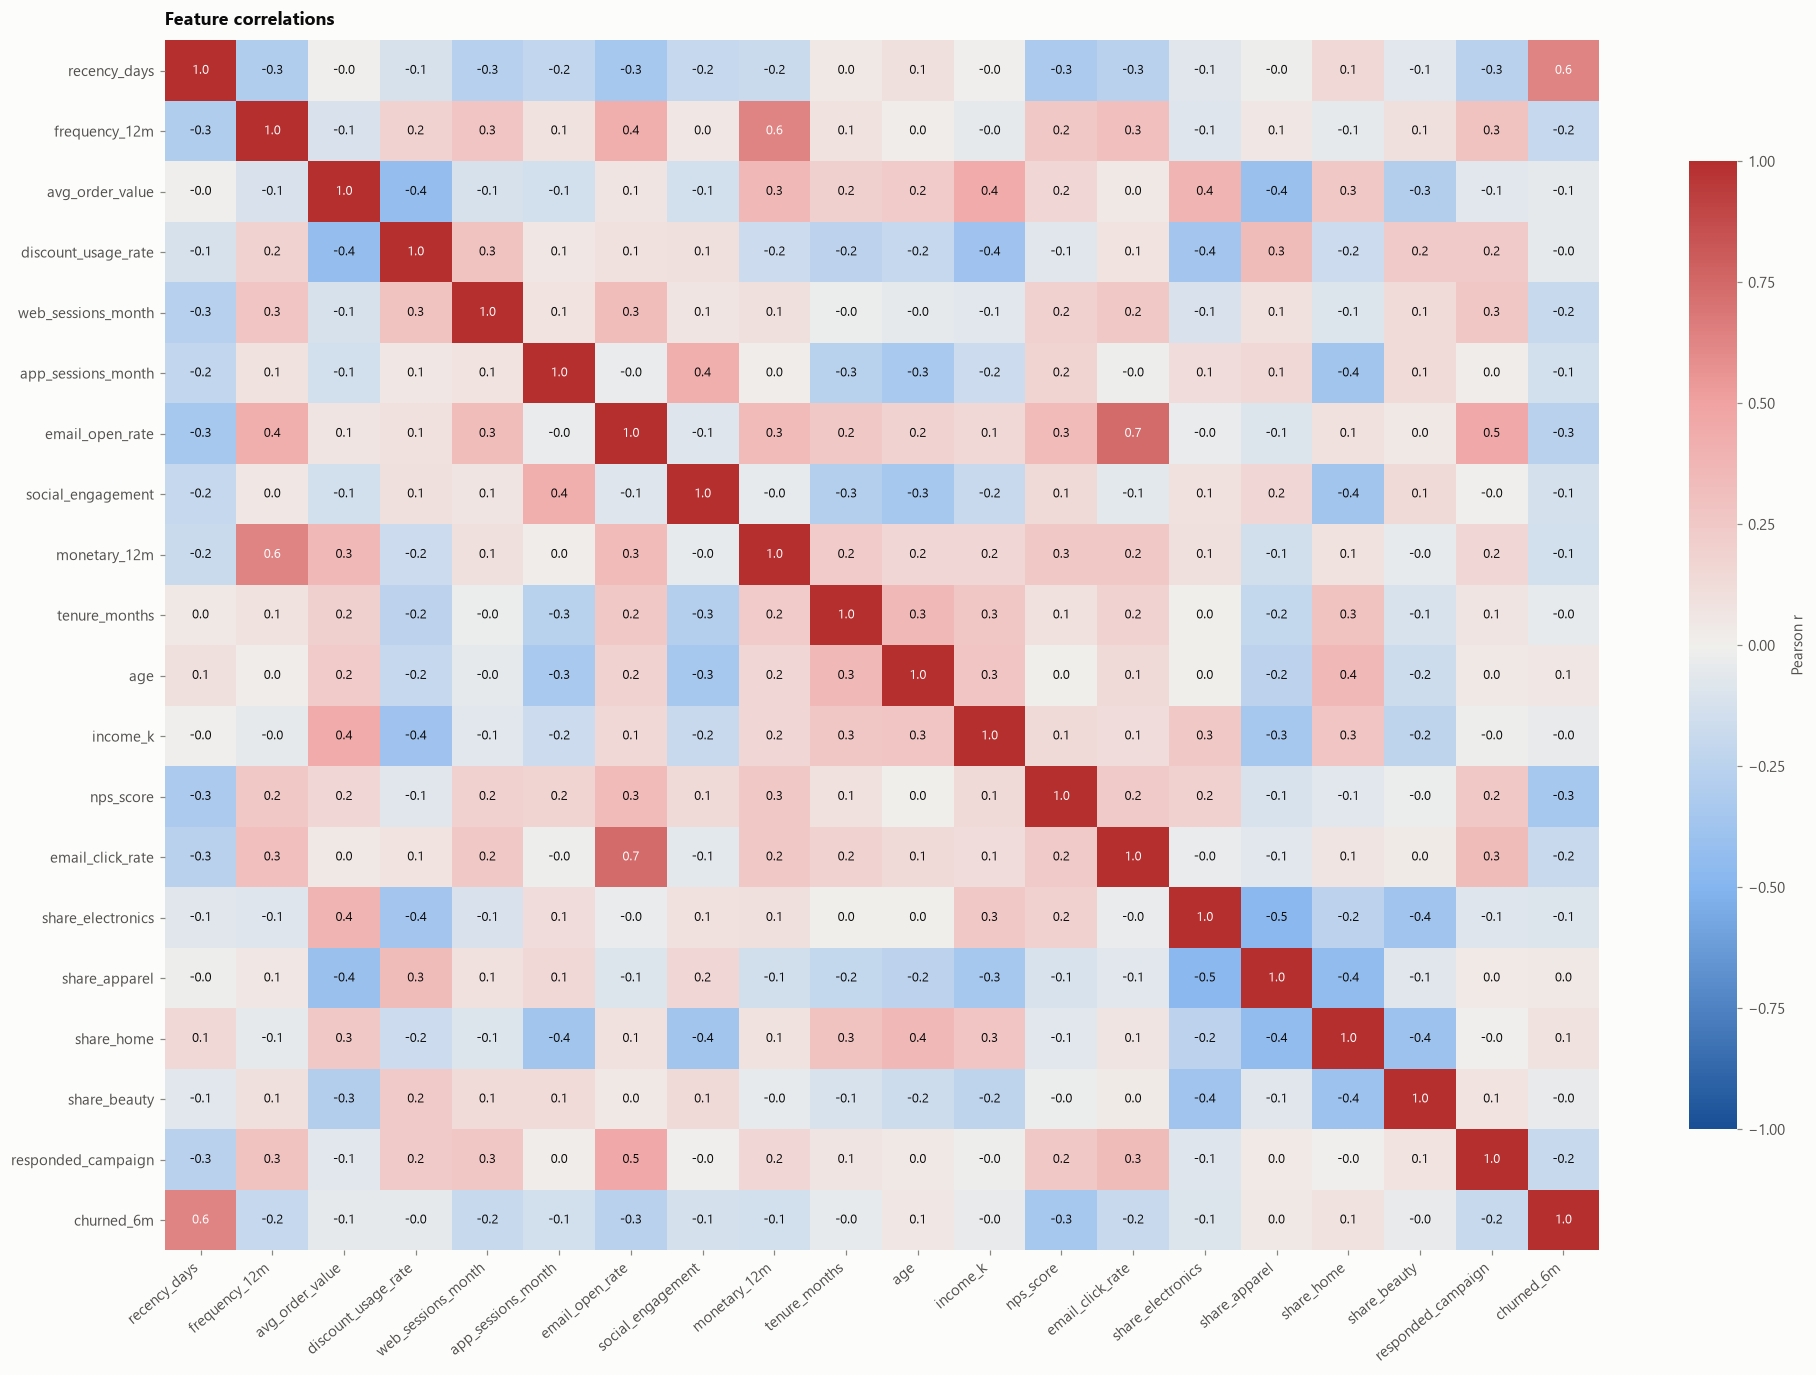

In [6]:
corr = df[PROFILE_FEATURES].corr()
P.plot_heatmap(corr, title="Feature correlations", fmt="{:.1f}", vlim=1, cbar_label="Pearson r");

## 2. Baseline: RFM segmentation

The classic marketing approach scores each customer 1-5 on **R**ecency, **F**requency and
**M**onetary value and maps score combinations to named groups. It's simple and explainable, but it
only uses three dimensions and ignores *how* customers engage (channels, discounts, email).

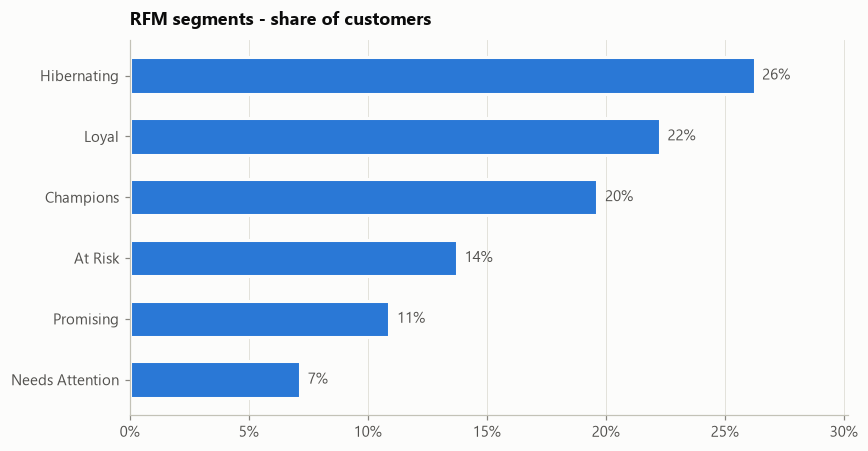

In [7]:
df = df.join(rfm_scores(df))
rfm_share = df.rfm_segment.value_counts(normalize=True)
P.plot_barh(rfm_share, title="RFM segments - share of customers");

In [8]:
df.groupby("rfm_segment")[["monetary_12m", "responded_campaign", "churned_6m"]].mean().sort_values("monetary_12m", ascending=False)

,monetary_12m,responded_campaign,churned_6m
rfm_segment,,,
Champions,"2,776.25",0.45,0.03
At Risk,"1,286.90",0.24,0.14
Loyal,"1,069.16",0.39,0.04
Needs Attention,177.52,0.20,0.07
Promising,176.41,0.27,0.06
Hibernating,162.23,0.05,0.41


## 3. Behavioural clustering

**Inputs:** 8 behavioural features. Demographics (age, income, region) are left out on purpose so
segments describe what customers *do*; demographics are used afterwards to profile the segments.

**Preprocessing:** `log1p` on skewed counts/amounts, then standardisation so every feature carries equal weight.

In [9]:
prep = cluster_preprocessor()
X = prep.fit_transform(df[CLUSTER_FEATURES])
X.shape

(8000, 8)

### Choosing the number of segments

No single metric decides *k*, so we look at four:

* **Elbow:** where adding clusters stops reducing within-cluster variance much
* **Silhouette:** how well separated the clusters are
* **Bootstrap stability:** whether refitting on 80% subsamples gives the same clusters (ARI)
* **GMM BIC:** model fit penalised for complexity

In [10]:
K = range(2, 9)
k_scores = evaluate_k(X, K)
stability = stability_by_k(X, K)
bic = gmm_bic(X, K)
k_scores.join(stability).join(bic)

,inertia,silhouette,calinski_harabasz,davies_bouldin,stability,bic
k,,,,,,
2,"44,525.78",0.29,"3,498.08",1.40,1.00,"155,193.45"
3,"38,089.03",0.26,"2,720.08",1.65,0.99,"152,051.54"
4,"32,670.94",0.28,"2,555.87",1.44,0.99,"151,408.06"
5,"28,848.44",0.25,"2,435.46",1.46,0.99,"150,763.46"
6,"27,789.12",0.21,"2,083.34",1.60,0.91,"150,029.05"
7,"26,902.84",0.18,"1,836.97",1.92,0.79,"149,988.00"
8,"25,997.87",0.16,"1,668.89",2.06,0.81,"149,009.94"


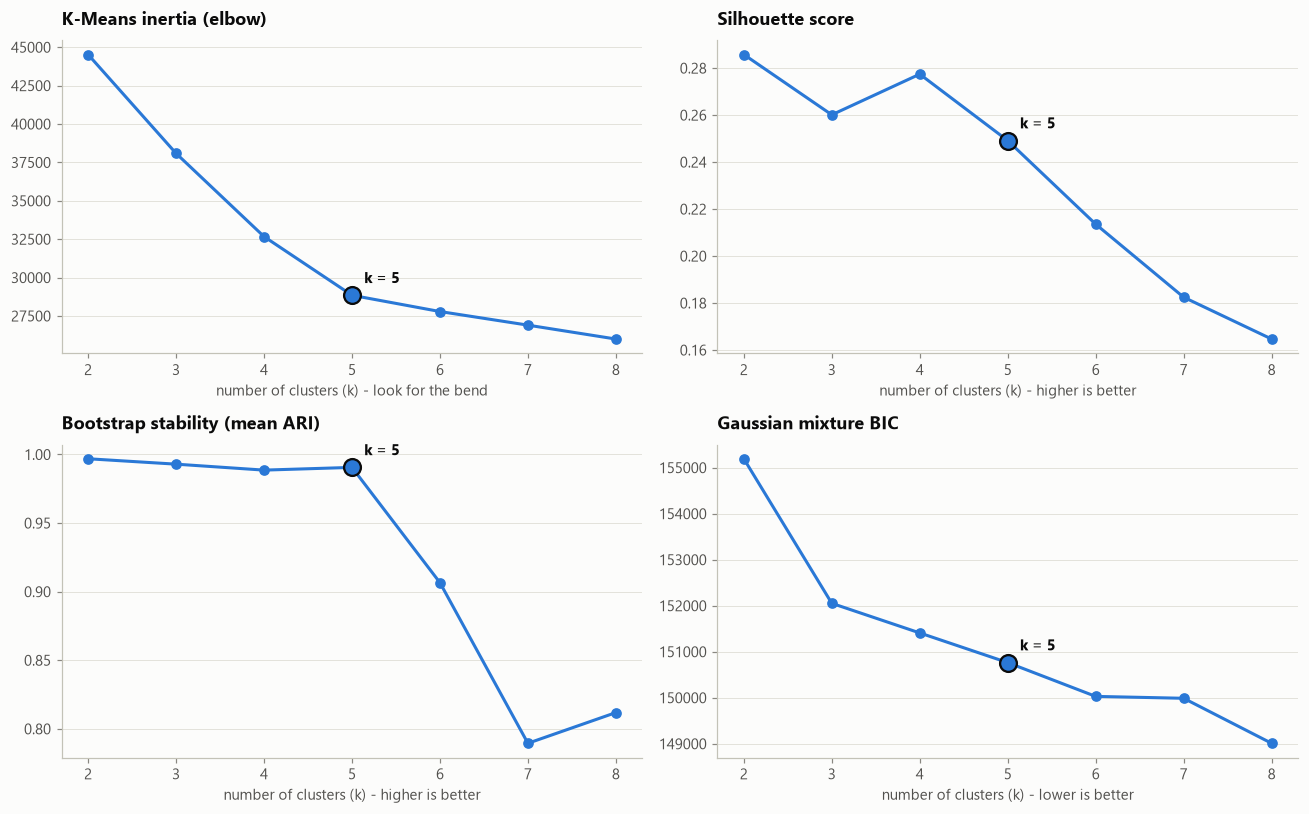

In [11]:
CHOSEN_K = 5
P.plot_k_selection(k_scores, stability, bic, CHOSEN_K);

**Decision: k = 5.** The elbow bends at 5. Bootstrap stability stays near 0.99 up to k = 5 and
then drops sharply, so solutions with more clusters aren't reproducible. Silhouette is highest at
k = 2, but two segments are too coarse to act on. BIC keeps decreasing because full-covariance
mixtures keep fitting the skew, so it doesn't settle the question here.

### Comparing clustering algorithms at k = 5

In [12]:
comparison, all_labels = compare_algorithms(X, CHOSEN_K, truth=df.true_persona)
comparison

,silhouette,calinski_harabasz,davies_bouldin,ARI_vs_hidden_persona
algorithm,,,,
K-Means,0.25,"2,435.46",1.46,0.86
Gaussian Mixture,0.21,"1,815.31",2.14,0.71
Agglomerative (Ward),0.23,"2,255.05",1.53,0.80


K-Means scores best on every internal metric (higher silhouette and Calinski-Harabasz, lower
Davies-Bouldin) and also recovers the hidden personas best (Adjusted Rand Index). We keep K-Means.

*The ARI column is only available because the data is synthetic.*

## 4. Segment profiles

Clusters come out as arbitrary numbers. To name them, each cluster's profile is scored against
five business-hypothesis archetypes and matched one-to-one (Hungarian algorithm).

In [13]:
df["cluster"] = all_labels["K-Means"]
z = index_vs_average(df, "cluster", PROFILE_FEATURES)
names = name_segments(z)
df["segment"] = df.cluster.map(names)

SEGMENTS = ["Loyal High-Value", "Bargain Hunters", "Digital Natives", "Occasional Big Spenders", "At-Risk Lapsed"]
COLORS = P.segment_colors(SEGMENTS)
names

{0: 'Occasional Big Spenders',
 1: 'Bargain Hunters',
 2: 'At-Risk Lapsed',
 3: 'Digital Natives',
 4: 'Loyal High-Value'}

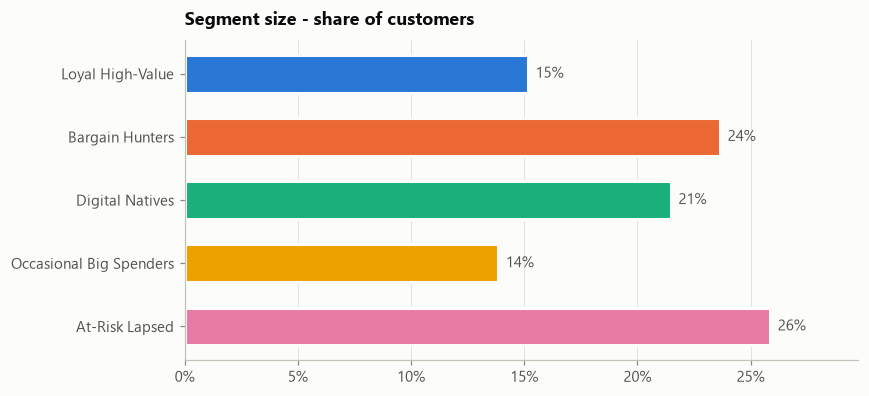

In [14]:
sizes = df.segment.value_counts(normalize=True).reindex(SEGMENTS)
P.plot_barh(sizes, colors=COLORS, title="Segment size - share of customers");

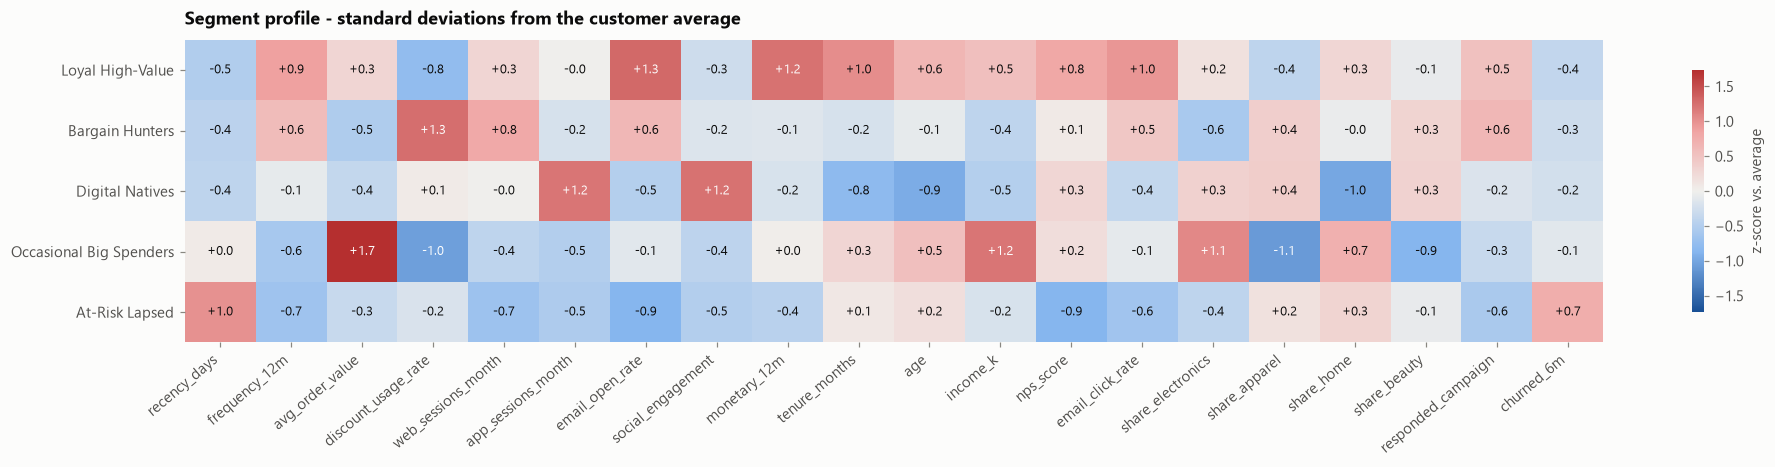

In [15]:
z_named = index_vs_average(df, "segment", PROFILE_FEATURES).reindex(SEGMENTS)
P.plot_heatmap(z_named, title="Segment profile - standard deviations from the customer average",
               cbar_label="z-score vs. average");

In [16]:
profile = profile_segments(df, "segment", PROFILE_FEATURES).reindex(SEGMENTS)
profile.T

segment,Loyal High-Value,Bargain Hunters,Digital Natives,Occasional Big Spenders,At-Risk Lapsed
customers,"1,213.00","1,892.00","1,718.00","1,108.00","2,069.00"
share,0.15,0.24,0.21,0.14,0.26
recency_days,14.73,25.71,29.87,89.48,216.74
frequency_12m,22.32,18.37,9.83,3.03,2.05
avg_order_value,156.03,40.61,63.64,361.13,66.88
discount_usage_rate,0.17,0.74,0.40,0.09,0.33
web_sessions_month,8.13,11.80,5.85,2.99,0.96
app_sessions_month,6.04,3.99,18.72,1.04,0.56
email_open_rate,0.67,0.49,0.20,0.30,0.10
social_engagement,1.99,2.81,12.26,1.06,0.48


### Segment map

PCA projects the 8 standardised behavioural features onto 2 dimensions. Each panel highlights one
segment against the full customer base, so segments can be compared without telling five colours
apart in one crowded scatter.

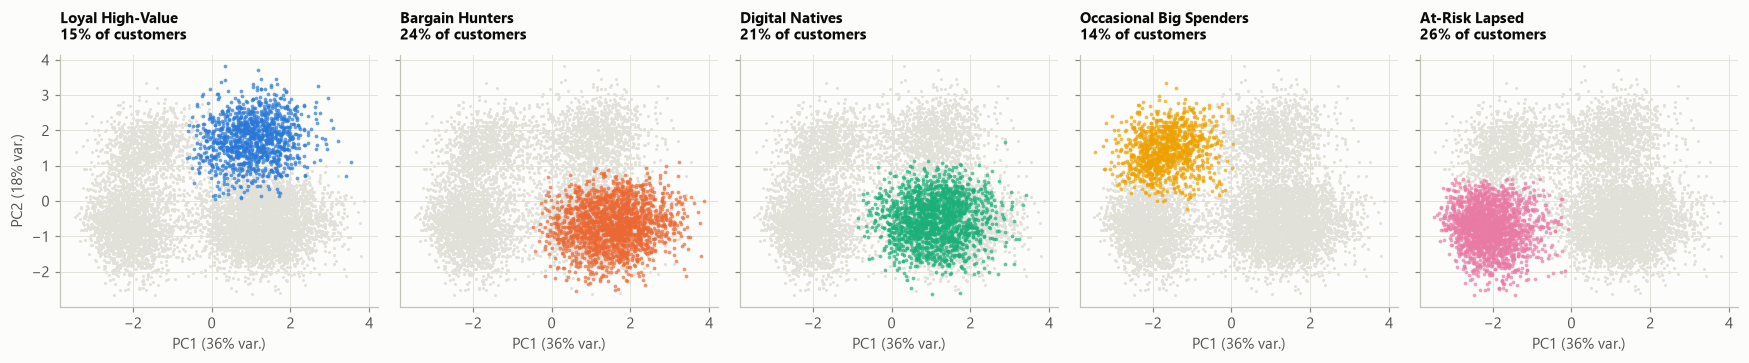

In [17]:
pca = PCA(n_components=2, random_state=42).fit(X)
coords = pca.transform(X)
ev = pca.explained_variance_ratio_
P.plot_segment_map(coords, df.segment.values, COLORS,
                   axis_labels=(f"PC1 ({ev[0]:.0%} var.)", f"PC2 ({ev[1]:.0%} var.)"));

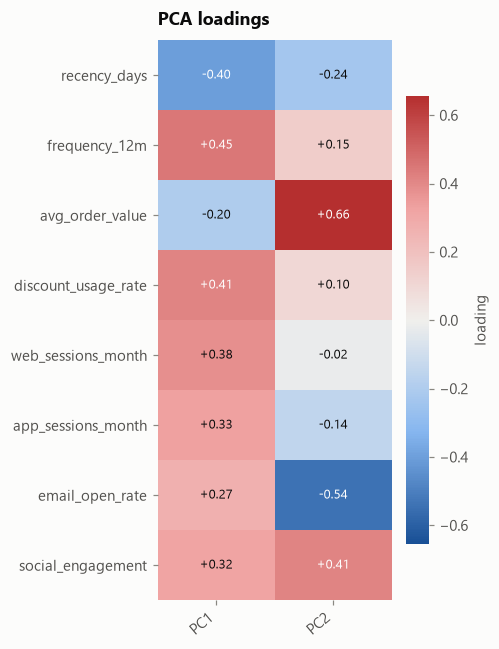

In [18]:
loadings = pd.DataFrame(pca.components_.T, index=CLUSTER_FEATURES, columns=["PC1", "PC2"])
P.plot_heatmap(loadings, title="PCA loadings", fmt="{:+.2f}", cbar_label="loading");

### Validation

**Against the hidden personas:** how many customers of each true persona ended up in each segment.

**Against RFM:** behavioural segments cut across the RFM groups. For example, RFM "Champions"
mix loyal customers with deal-driven Bargain Hunters, who need very different messages.

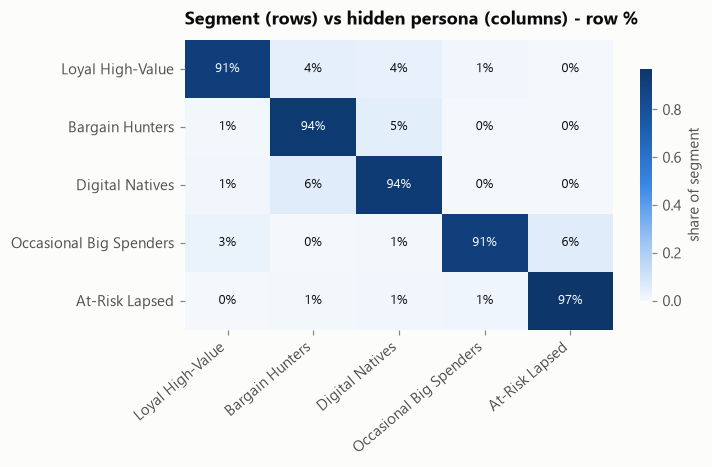

In [19]:
truth_ct = pd.crosstab(df.segment, df.true_persona, normalize="index").reindex(index=SEGMENTS, columns=SEGMENTS)
P.plot_heatmap(truth_ct, title="Segment (rows) vs hidden persona (columns) - row %",
               cmap=P.SEQ_CMAP, fmt="{:.0%}", cbar_label="share of segment");

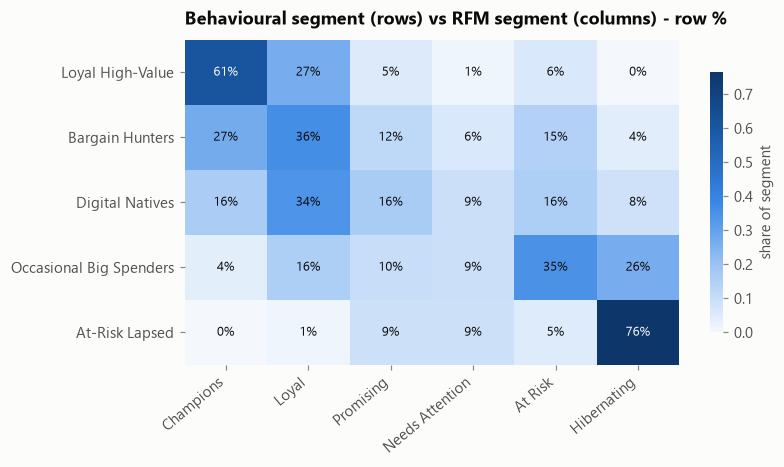

In [20]:
rfm_order = ["Champions", "Loyal", "Promising", "Needs Attention", "At Risk", "Hibernating"]
rfm_ct = pd.crosstab(df.segment, df.rfm_segment, normalize="index").reindex(index=SEGMENTS, columns=rfm_order)
P.plot_heatmap(rfm_ct, title="Behavioural segment (rows) vs RFM segment (columns) - row %",
               cmap=P.SEQ_CMAP, fmt="{:.0%}", cbar_label="share of segment");

## 5. Explaining segments with a random forest

A random forest trained to predict the segment from **all** customer attributes (including
demographics not used in clustering) does two jobs:

* **Deployment:** new customers can be assigned to a segment without re-clustering
* **Explanation:** permutation importance shows which attributes separate the segments

In [21]:
seg_model, seg_report, seg_importance = train_segment_classifier(df)
seg_report.loc[SEGMENTS + ["macro avg"], ["precision", "recall", "f1-score", "support"]]

,precision,recall,f1-score,support
Loyal High-Value,0.97,0.93,0.95,303.00
Bargain Hunters,0.96,0.95,0.95,473.00
Digital Natives,0.91,0.95,0.93,430.00
Occasional Big Spenders,0.97,0.94,0.96,277.00
At-Risk Lapsed,0.97,0.97,0.97,517.00
macro avg,0.95,0.95,0.95,"2,000.00"


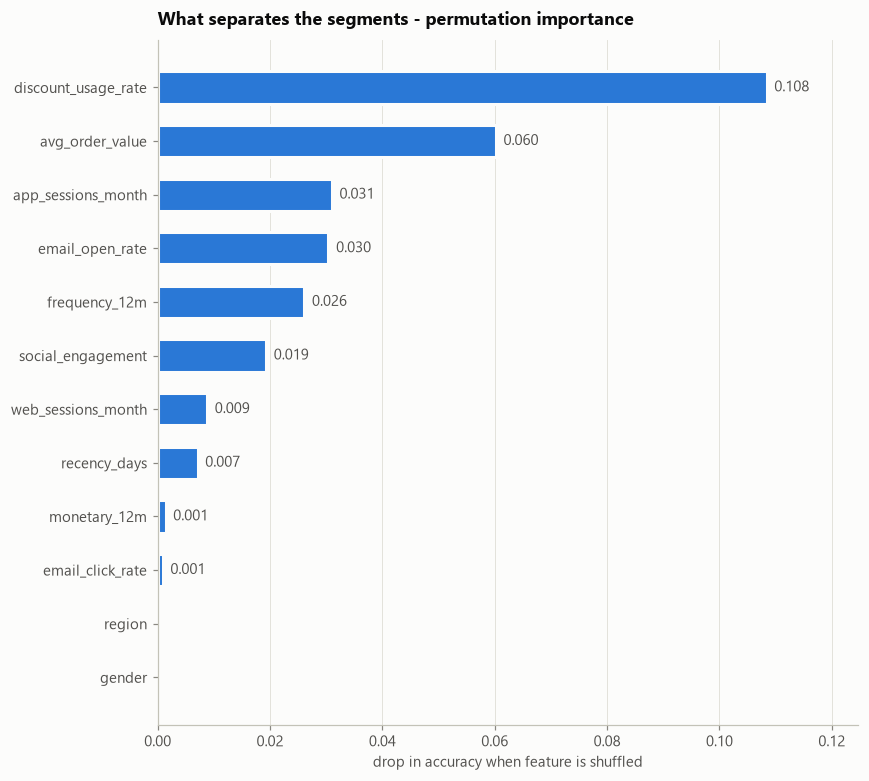

In [22]:
P.plot_barh(seg_importance.head(12), title="What separates the segments - permutation importance",
            fmt="{:.3f}", xlabel="drop in accuracy when feature is shuffled");

## 6. Campaign response model

Who will respond to the next promotional email? Two models are compared on a 30% hold-out set:
a regularised **logistic regression** (interpretable baseline) and **gradient boosting**
(captures non-linearities). The segment label is included as a feature.

In [23]:
response_results, X_test, y_test = train_response_models(df)
pd.Series({k: v["auc"] for k, v in response_results.items()}, name="ROC AUC").to_frame()

,ROC AUC
Logistic regression,0.83
Gradient boosting,0.82


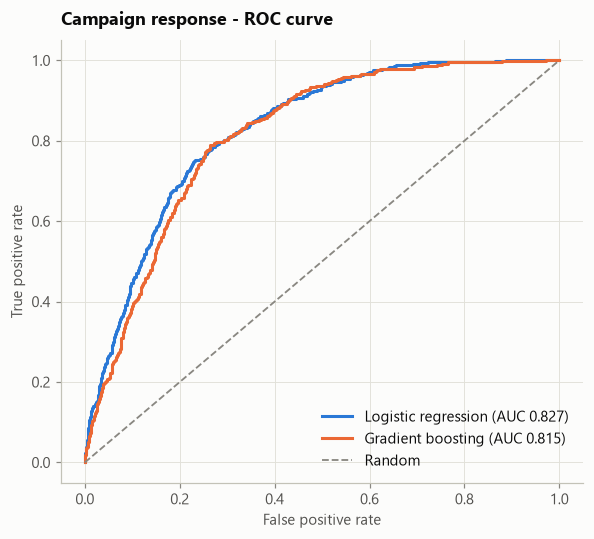

In [24]:
P.plot_roc(response_results);

The simpler logistic regression matches or beats gradient boosting here. The response signal is
mostly additive (email engagement, discount affinity, recency), so the interpretable model is the
one to deploy. The best model by AUC is used for the gains analysis below.

In [25]:
best_name = max(response_results, key=lambda k: response_results[k]["auc"])
best = response_results[best_name]
gains = gains_table(y_test, best["scores"])
print(f"Using: {best_name}")
gains[["customers", "responders", "response_rate", "lift", "cum_pct_responders"]]

Using: Logistic regression


,customers,responders,response_rate,lift,cum_pct_responders
decile,,,,,
1,240,159,0.66,2.49,0.25
2,240,136,0.57,2.13,0.46
3,240,117,0.49,1.83,0.65
4,240,83,0.35,1.30,0.78
5,240,54,0.23,0.85,0.86
6,240,40,0.17,0.63,0.92
7,240,30,0.12,0.47,0.97
8,240,16,0.07,0.25,1.00
9,240,2,0.01,0.03,1.00


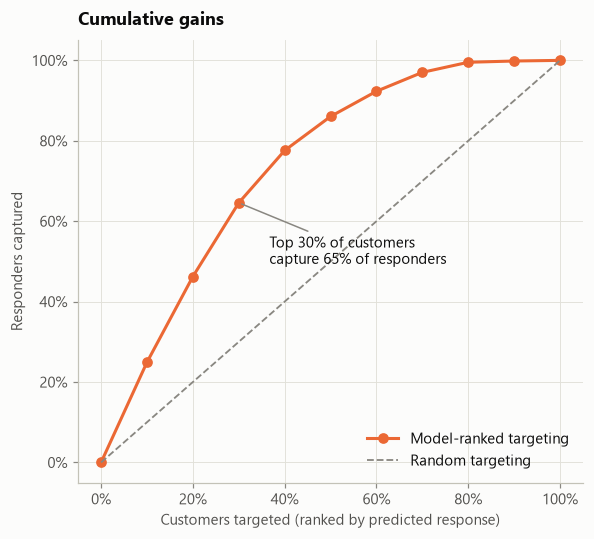

In [26]:
P.plot_gains(gains);

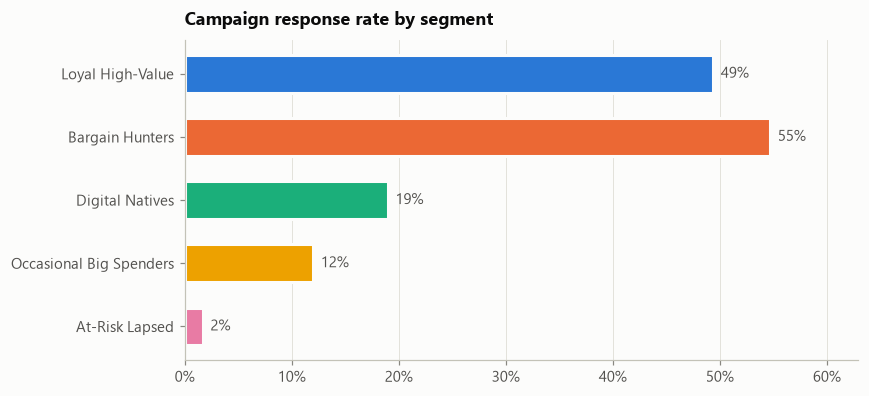

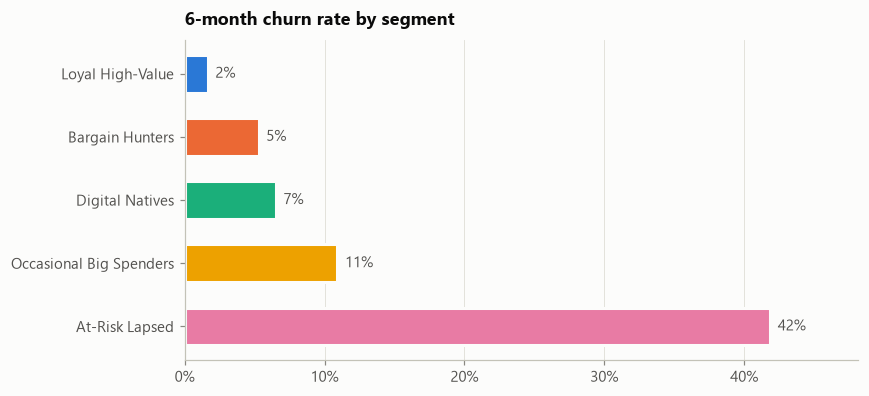

In [27]:
fig_r = P.plot_barh(df.groupby("segment").responded_campaign.mean().reindex(SEGMENTS), colors=COLORS,
                    title="Campaign response rate by segment")
fig_c = P.plot_barh(df.groupby("segment").churned_6m.mean().reindex(SEGMENTS), colors=COLORS,
                    title="6-month churn rate by segment")

## 7. Marketing playbook

Segment economics plus the response model's predicted propensity give each segment a clear action.

In [28]:
df["p_response"] = best["model"].predict_proba(df[X_test.columns])[:, 1]
revenue_share = df.groupby("segment").monetary_12m.sum() / df.monetary_12m.sum()

ACTIONS = {
    "Loyal High-Value": "VIP / loyalty tier, early access, referral asks. Protect, don't discount",
    "Bargain Hunters": "Targeted promo codes and bundles to lift basket size; cap discount depth",
    "Digital Natives": "App push and social / UGC campaigns; mobile-first offers",
    "Occasional Big Spenders": "Personalised premium recommendations around purchase cycles",
    "At-Risk Lapsed": "Win-back sequence; suppress from costly channels if no reaction",
}
playbook = pd.DataFrame({
    "customers": df.segment.value_counts(),
    "revenue_share": revenue_share,
    "avg_revenue": df.groupby("segment").monetary_12m.mean(),
    "response_rate": df.groupby("segment").responded_campaign.mean(),
    "pred_response": df.groupby("segment").p_response.mean(),
    "churn_rate": df.groupby("segment").churned_6m.mean(),
    "action": pd.Series(ACTIONS),
}).reindex(SEGMENTS)
playbook.style.format({
    "customers": "{:,}", "revenue_share": "{:.0%}", "avg_revenue": "${:,.0f}",
    "response_rate": "{:.0%}", "pred_response": "{:.0%}", "churn_rate": "{:.0%}",
}).set_properties(subset=["action"], **{"text-align": "left", "white-space": "normal"})

,customers,revenue_share,avg_revenue,response_rate,pred_response,churn_rate,action
Loyal High-Value,"1,213",52%,"$3,539",49%,51%,2%,"VIP / loyalty tier, early access, referral asks. Protect, don't discount"
Bargain Hunters,"1,892",17%,$755,55%,55%,5%,Targeted promo codes and bundles to lift basket size; cap discount depth
Digital Natives,"1,718",13%,$626,19%,19%,7%,App push and social / UGC campaigns; mobile-first offers
Occasional Big Spenders,"1,108",15%,"$1,086",12%,11%,11%,Personalised premium recommendations around purchase cycles
At-Risk Lapsed,"2,069",3%,$136,2%,2%,42%,Win-back sequence; suppress from costly channels if no reaction


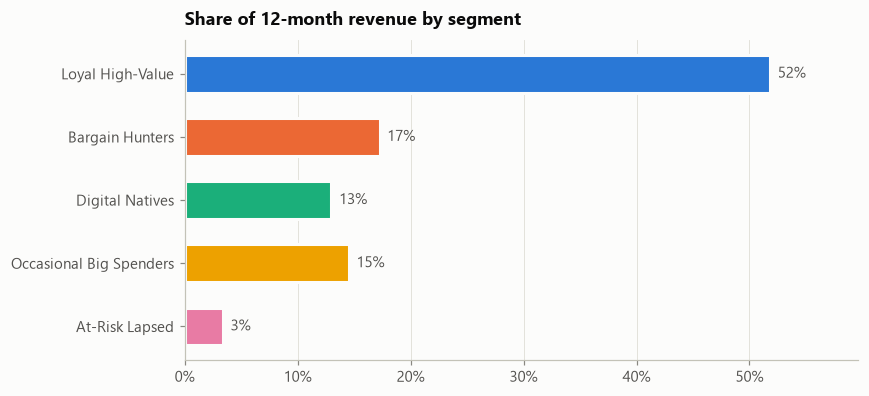

In [29]:
fig = P.plot_barh(revenue_share.reindex(SEGMENTS), colors=COLORS, title="Share of 12-month revenue by segment")

In [30]:
DATA_PROCESSED.mkdir(parents=True, exist_ok=True)
out_cols = ["customer_id", "segment", "rfm_segment", "R", "F", "M", "p_response"]
df[out_cols].to_csv(DATA_PROCESSED / "customer_segments.csv", index=False)
print(f"Saved {len(df):,} rows to {DATA_PROCESSED / 'customer_segments.csv'}")

Saved 8,000 rows to C:\Users\ashal\segmentation-datascience-ltcs\data\processed\customer_segments.csv


## 8. Key findings

1. **Five stable behavioural segments.** K-Means (k = 5, chosen by elbow + bootstrap stability)
   beat GMM and Ward clustering and recovered the hidden personas with ARI 0.86. A random forest
   reproduces the segments from raw attributes with a macro F1 of 0.95, so new customers can be scored directly.
2. **Revenue is concentrated.** *Loyal High-Value* customers are 15% of the base but generate
   **52% of revenue** with 2% churn, so protecting them matters more than acquiring them.
3. **Discount usage and order value define the segments.** These two features carry the most
   permutation importance. Demographics (region, gender) add almost nothing.
4. **RFM has a blind spot.** RFM labels 61% of *Occasional Big Spenders* "At Risk" or
   "Hibernating", even though they spend over $1,000 a year in a few large orders. Win-back
   discounts would waste margin on this group.
5. **Targeting beats blasting.** The logistic model (AUC 0.83, slightly ahead of gradient boosting)
   captures **65% of responders by contacting only the top 30%**, with 2.5x lift in the top decile.
6. **At-Risk Lapsed** is the largest segment (26%) but has a 2% response rate and 42% churn. Move it to a
   low-cost win-back flow instead of the main promotional calendar.

**Next steps with real data:** validate segment stability over time, A/B test segment-specific
offers, and model *uplift* (incremental response) rather than raw response.